# 📊 Análisis de Varianza (ANOVA y ANOVA Factorial) - CLV México
### **Evaluación de Factores Críticos en Ventas, Operaciones e Inventario**
---


#### **Equipo de Trabajo:**

| Nombre del Alumno | Matrícula |
| :--- | :---: |
| **Ian Kaled Sandoval Gines** | `A01738687` |
| **André Guillermo Carvajal Flores** | `A01738830` |
| **Johan André Heredia Zazueta** | `A01738019` |
| **Sebastián Olivares Puente** | `A01737568` |
| **Juan Pablo Solís Croda** | `A01738139` |

---

### Resumen Estadístico:
* **Preprocesamiento Riguroso:** Normalización de texto, Winsorización (percentiles 1%-99%) para controlar transacciones atípicas de equipos de alto valor sin eliminar filas, y transformación $\log(1+x)$ para corregir asimetría positiva.
* **Verificación de Supuestos:** Prueba de **Levene** para evaluar igualdad de varianzas (homocedasticidad).
* **Modelos OLS:** Tablas ANOVA **Tipo II** para manejar diseños con muestras desbalanceadas sin sesgo de orden.
* **Tamaño del Efecto:** Cálculo de **Eta cuadrado parcial ($\eta_p^2$)** para determinar la relevancia práctica de los factores más allá del $p$-valor.
* **Comparaciones Múltiples:** Pruebas Post-Hoc de **Tukey HSD** con control de tasa de error familiar ($\alpha = 0.05$).
* **Alcance:** **10 casos de negocio** que cubren facturación, prospección CRM, existencias, compras y rotación logística.


## 1. Importación de Librerías y Configuración del Entorno
Aquí importamos todas las herramientas necesarias:
* **`pandas` y `numpy`**: para manipular tablas, filtrar datos y hacer cálculos matemáticos.
* **`scipy.stats`**: para calcular pruebas de igualdad de varianzas (test de Levene).
* **`statsmodels`**: para ajustar el modelo lineal (`ols`) y generar la tabla formal de ANOVA (`anova_lm`).
* **`matplotlib` y `seaborn`**: para graficar diagramas de caja (*boxplots*) y gráficos de interacción.


In [22]:
# Importamos librerías básicas para manejar nuestras tablas y matrices
import os
import sys
import unicodedata
from pathlib import Path
import warnings
warnings.filterwarnings("ignore") # Silenciamos advertencias menores para mantener limpia la salida

import numpy as np # Operaciones numéricas y matemáticas
import pandas as pd # Manipulación de DataFrames y lectura de archivos Excel

# Importamos librerías para visualización de datos
import matplotlib.pyplot as plt # Control fino de figuras y tamaños
import seaborn as sns # Gráficos estadísticos atractivos

# Importamos las herramientas estadísticas formales
from scipy import stats # Test de Levene para verificar supuestos
import statsmodels.api as sm
from statsmodels.formula.api import ols # Ajuste de modelos lineales por mínimos cuadrados
from statsmodels.stats.anova import anova_lm # Cálculo de la tabla ANOVA Tipo II
from statsmodels.stats.multicomp import pairwise_tukeyhsd # Prueba post-hoc de Tukey

# Configuramos un estilo visual limpio y consistente para nuestros gráficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5) # Tamaño estándar de figuras
plt.rcParams["font.sans-serif"] = "Arial" # Tipografía legible


## 2. Configuración Directa de Rutas
Definimos la ruta directa hacia nuestra carpeta de `Datos Reales` y asignamos la ubicación de cada archivo de Excel.


In [23]:
# Definimos la carpeta exacta donde guardamos nuestros datos reales
RUTA_DATOS = Path("Datos Reales")

# Asignamos directamente las rutas a nuestros archivos de Excel
ARCHIVO_CLV_V2 = RUTA_DATOS / "Datos_CLV_2026_Tec_v2.xlsx" # Archivo principal del reto
ARCHIVO_COMPLEMENTARIO = RUTA_DATOS / "Datos_Complementarios_CLV.xlsx" # Base de datos complementaria
ARCHIVO_TIEMPOS = RUTA_DATOS / "Relación de tiempos de entrega.xlsx" # Tiempos de entrega de proveedores

# Creamos la carpeta donde guardaremos los gráficos de nuestros análisis
DIR_IMG = Path("img_reporte")
DIR_IMG.mkdir(exist_ok=True) # Si no existe, la creamos automáticamente

# Mostramos las rutas configuradas
print("Rutas configuradas correctamente:")
print("• Carpeta de datos:", RUTA_DATOS)
print("• Archivo Principal:", ARCHIVO_CLV_V2)
print("• Archivo Complementario:", ARCHIVO_COMPLEMENTARIO)
print("• Archivo Tiempos:", ARCHIVO_TIEMPOS)


Rutas configuradas correctamente:
• Carpeta de datos: Datos Reales
• Archivo Principal: Datos Reales/Datos_CLV_2026_Tec_v2.xlsx
• Archivo Complementario: Datos Reales/Datos_Complementarios_CLV.xlsx
• Archivo Tiempos: Datos Reales/Relación de tiempos de entrega.xlsx


## 3. Funciones de Preprocesamiento Estadístico
Antes de correr cualquier prueba estadística, debemos asegurarnos de que los datos estén limpios y cumplan con los supuestos matemáticos de ANOVA:
1. **Normalización de texto:** Para que `"Vita"`, `"VITA"` o `" vita "` sean tratados como la misma categoría.
2. **Tratamiento de Outliers (Winsorización):** En ventas y almacenes hay transacciones atípicas enormes (por ejemplo, la compra de un horno dental muy costoso). Si borramos esas filas perdemos información valiosa, pero si las dejamos intactas distorsionan los promedios. Por eso usamos **Winsorización** (recortamos los valores extremos al percentil 1% y 99%).
3. **Transformación Logarítmica $\log(1+x)$:** Las variables monetarias y de existencias tienen un fuerte sesgo a la derecha. Aplicar el logaritmo hace que la distribución sea simétrica (acampanada) y ayuda a que las varianzas sean comparables.


In [24]:
# Función para limpiar textos y estandarizar categorías
def normalizar_texto(valor):
    if pd.isna(valor): # Si el valor viene vacío
        return "" # Regresamos una cadena vacía
    texto = str(valor).strip().lower() # Quitamos espacios en las orillas y pasamos a minúsculas
    # Eliminamos acentos y tildes para evitar duplicados como 'México' y 'Mexico'
    return "".join(
        c for c in unicodedata.normalize("NFD", texto)
        if unicodedata.category(c) != "Mn"
    )

# Función para tratar outliers usando Winsorización
def tratar_outliers_winsorize(serie, lim_inferior=0.01, lim_superior=0.99):
    serie_valida = serie.dropna() # Filtramos nulos para calcular percentiles reales
    if serie_valida.empty: # Si no hay datos válidos
        return serie # Regresamos la serie tal cual
    q_inf = serie_valida.quantile(lim_inferior) # Calculamos el percentil 1%
    q_sup = serie_valida.quantile(lim_superior) # Calculamos el percentil 99%
    # Limitamos los valores extremos a esos umbrales (no los borramos, solo los suavizamos)
    return serie.clip(lower=q_inf, upper=q_sup)

# Función para calcular el tamaño del efecto (Eta cuadrado parcial: η_p²)
def calcular_eta_cuadrado_parcial(tabla_anova):
    # Obtenemos la suma de cuadrados residual (del error)
    ss_error = tabla_anova.loc["Residual", "sum_sq"] if "Residual" in tabla_anova.index else 0
    etas = {} # Diccionario donde guardaremos los resultados
    for factor in tabla_anova.index:
        if factor not in ["Residual", "Intercept"]:
            ss_factor = tabla_anova.loc[factor, "sum_sq"] # Suma de cuadrados explicada por el factor
            if (ss_factor + ss_error) > 0: # Evitamos división entre cero
                etas[factor] = ss_factor / (ss_factor + ss_error) # Calculamos la proporción explicada
            else:
                etas[factor] = 0.0
    return etas


## 4.ANOVA en Funciones
Definimos dos funciones generales para automatizar el análisis:
* **`ejecutar_anova_unifactorial`**: Ejecuta ANOVA de 1 factor, evalúa la igualdad de varianzas con el test de Levene, corre la prueba de comparaciones múltiples de Tukey (si hay diferencias) y genera un diagrama de caja.
* **`ejecutar_anova_multifactorial`**: Modela dos factores con su **efecto de interacción**, genera la tabla ANOVA Tipo II y dibuja un gráfico de líneas de interacción de medias.


In [25]:
# Función para ejecutar ANOVA de 1 Vía (Unifactorial)
def ejecutar_anova_unifactorial(df, y_col, factor_col, titulo_caso, nombre_grafico=None):
    print(f"\n{'='*75}\n📌 {titulo_caso.upper()}\n{'='*75}")
    # Seleccionamos solo las dos columnas que nos interesan y eliminamos nulos
    datos = df[[y_col, factor_col]].dropna().copy()
    
    # Filtramos para quedarnos con grupos que tengan al menos 5 observaciones
    conteos = datos[factor_col].value_counts() # Contamos cuántos registros hay por grupo
    grupos_validos = conteos[conteos >= 5].index.tolist() # Solo grupos representativos
    datos = datos[datos[factor_col].isin(grupos_validos)].copy() # Filtramos los datos
    
    if len(grupos_validos) < 2: # Necesitamos al menos 2 grupos para comparar
        print(f"⚠️ No hay suficientes grupos válidos para '{factor_col}'. Se omite.")
        return None

    # Verificamos el supuesto de igualdad de varianzas (Prueba de Levene)
    grupos_valores = [datos[datos[factor_col] == g][y_col].values for g in grupos_validos]
    try:
        stat_levene, p_levene = stats.levene(*grupos_valores) # Corremos el test de Levene
    except Exception:
        stat_levene, p_levene = np.nan, np.nan

    # Ajustamos el modelo lineal usando mínimos cuadrados ordinarios (OLS)
    formula = f"Q('{y_col}') ~ C(Q('{factor_col}'))" # Indicamos que el factor es categórico
    modelo = ols(formula, data=datos).fit() # Ajustamos el modelo
    tabla_anova = anova_lm(modelo, typ=2) # Generamos la tabla ANOVA Tipo II
    
    # Extraemos métricas principales de la tabla
    eta_dict = calcular_eta_cuadrado_parcial(tabla_anova) # Calculamos Eta²
    factor_key = [k for k in tabla_anova.index if k != "Residual"][0]
    f_val = tabla_anova.loc[factor_key, "F"] # Estadístico F
    p_val = tabla_anova.loc[factor_key, "PR(>F)"] # p-valor
    eta_val = eta_dict.get(factor_key, 0.0) # Tamaño del efecto

    # Mostramos los resultados en un formato fácil de leer
    print(f"• Factor evaluado: {factor_col} ({len(grupos_validos)} niveles)")
    print(f"• Variable respuesta: {y_col} (Total de casos: {len(datos):,})")
    print(f"• Homocedasticidad (Levene): Stat = {stat_levene:.3f}, p-valor = {p_levene:.4e}")
    print(f"• Estadístico F: {f_val:.3f} | p-valor: {p_val:.4e}")
    print(f"• Tamaño del efecto (Eta² parcial): {eta_val:.4f}")
    
    significativo = p_val < 0.05 # Si p < 0.05, rechazamos la hipótesis nula
    if significativo:
        print("• Conclusión: Sí existen diferencias significativas entre grupos (Rechaza H0).")
    else:
        print("• Conclusión: No hay evidencia de diferencias significativas (No rechaza H0).")

    # Si hay diferencias y son más de 2 grupos, hacemos la prueba de Tukey para ver cuáles difieren
    if significativo and len(grupos_validos) > 2:
        print("\n--- Pruebas Post-Hoc Tukey HSD (Top comparaciones) ---")
        try:
            tukey = pairwise_tukeyhsd(endog=datos[y_col], groups=datos[factor_col], alpha=0.05)
            resumen_tukey = pd.DataFrame(data=tukey._results_table.data[1:], columns=tukey._results_table.data[0])
            significativos = resumen_tukey[resumen_tukey["reject"] == True] # Solo pares con diferencia
            print(f"Pares con diferencia real: {len(significativos)} de {len(resumen_tukey)}")
            if not significativos.empty:
                print(significativos.head(5).to_string(index=False)) # Mostramos los primeros 5
        except Exception as e:
            print("No se pudo calcular Tukey:", e)

    # Generamos un gráfico de caja (Boxplot) para visualizar la distribución
    if nombre_grafico:
        plt.figure(figsize=(9, 5))
        orden = datos.groupby(factor_col)[y_col].median().sort_values(ascending=False).index
        sns.boxplot(data=datos, x=factor_col, y=y_col, order=orden, palette="Blues_r")
        plt.title(f"{titulo_caso}\n(F = {f_val:.2f}, p = {p_val:.3e}, η² = {eta_val:.3f})", fontweight="bold")
        plt.xlabel(factor_col)
        plt.ylabel(f"Valores transformados ({y_col})")
        plt.xticks(rotation=20, ha="right")
        plt.tight_layout()
        plt.savefig(DIR_IMG / f"{nombre_grafico}.png", dpi=150) # Guardamos la imagen
        plt.show() # Mostramos la gráfica en el notebook

    return {
        "Caso": titulo_caso,
        "Tipo": "1 Vía (Unifactorial)",
        "Variable_Y": y_col,
        "Factores": factor_col,
        "F_Statistic": round(f_val, 3),
        "P_Valor": p_val,
        "Eta_Cuadrado": round(eta_val, 4),
        "Significativo": significativo
    }

# Función para ejecutar ANOVA Multifactorial (2 Vías con Interacción)
def ejecutar_anova_multifactorial(df, y_col, factor1, factor2, titulo_caso, nombre_grafico=None):
    print(f"\n{'='*75}\n📌 {titulo_caso.upper()}\n{'='*75}")
    datos = df[[y_col, factor1, factor2]].dropna().copy()
    
    # Seleccionamos los niveles más comunes para asegurar que cada combinación tenga datos
    top_f1 = datos[factor1].value_counts().head(5).index.tolist()
    top_f2 = datos[factor2].value_counts().head(4).index.tolist()
    datos = datos[datos[factor1].isin(top_f1) & datos[factor2].isin(top_f2)].copy()

    # Planteamos el modelo con los efectos principales y su término de interacción (A * B)
    formula = f"Q('{y_col}') ~ C(Q('{factor1}')) + C(Q('{factor2}')) + C(Q('{factor1}')):C(Q('{factor2}'))"
    modelo = ols(formula, data=datos).fit() # Ajustamos el modelo lineal
    tabla_anova = anova_lm(modelo, typ=2) # Tabla ANOVA Tipo II
    eta_dict = calcular_eta_cuadrado_parcial(tabla_anova) # Calculamos tamaños de efecto

    print(f"• Factores evaluados: {factor1} × {factor2} (Muestras: {len(datos):,})")
    print(f"• Variable respuesta: {y_col}")
    print("\n--- Tabla ANOVA (Tipo II) ---")
    tabla_print = tabla_anova.copy()
    tabla_print["Eta_Parcial"] = [eta_dict.get(idx, np.nan) for idx in tabla_print.index]
    print(tabla_print.round(4).to_string())

    # Generamos el gráfico de interacción de medias
    if nombre_grafico:
        plt.figure(figsize=(9, 5))
        sns.pointplot(
            data=datos, x=factor1, y=y_col, hue=factor2,
            dodge=True, markers=["o", "s", "D", "^"], linestyles=["-", "--", "-.", ":"],
            errorbar=None, palette="Set1"
        )
        plt.title(f"{titulo_caso}\n(Gráfico de Interacción de Medias)", fontweight="bold")
        plt.xlabel(factor1)
        plt.ylabel(f"Media de {y_col}")
        plt.xticks(rotation=20, ha="right")
        plt.legend(title=factor2, bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout()
        plt.savefig(DIR_IMG / f"{nombre_grafico}.png", dpi=150)
        plt.show()

    interaccion_key = [k for k in tabla_anova.index if ":" in k][0]
    p_inter = tabla_anova.loc[interaccion_key, "PR(>F)"] # p-valor de la interacción
    inter_significativa = p_inter < 0.05
    print(f"• Interacción ({factor1} × {factor2}): p = {p_inter:.4e} -> {'Significativa' if inter_significativa else 'No significativa'}")

    return {
        "Caso": titulo_caso,
        "Tipo": "Multifactorial (2 Vías con Interacción)",
        "Variable_Y": y_col,
        "Factores": f"{factor1} × {factor2}",
        "F_Statistic": round(tabla_anova.loc[interaccion_key, "F"], 3),
        "P_Valor": p_inter,
        "Eta_Cuadrado": round(eta_dict.get(interaccion_key, 0.0), 4),
        "Significativo": inter_significativa
    }


In [26]:
# Lista donde iremos acumulando los resúmenes de cada uno de los 10 casos
resumen_global = []


## 5. Casos de Negocio en Ventas (`Ventas_CLV_2022_2026`)
En esta sección analizamos cómo se comporta el dinero facturado (`total_neto`):
* **Caso 1:** ¿El monto de venta cambia según el esquema de pago (Contado vs. Crédito vs. Tienda en Línea)?
* **Caso 2:** ¿El monto vendido varía significativamente entre los estados del país?
* **Caso 3:** ¿Existe interacción entre la marca comercial y el tipo de pago?



📌 CASO 1: IMPORTE FACTURADO POR TIPO DE PAGO (CONTADO VS CRÉDITO VS ONLINE)
• Factor evaluado: tipo_pago (2 niveles)
• Variable respuesta: log_total_neto (Total de casos: 16,175)
• Homocedasticidad (Levene): Stat = 608.697, p-valor = 5.8454e-132
• Estadístico F: 499.441 | p-valor: 5.5844e-109
• Tamaño del efecto (Eta² parcial): 0.0300
• Conclusión: Sí existen diferencias significativas entre grupos (Rechaza H0).


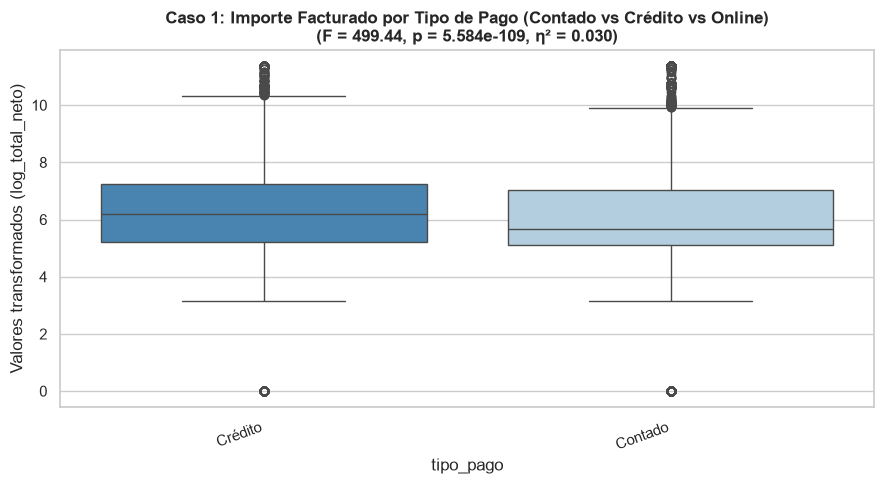


📌 CASO 2: IMPORTE FACTURADO SEGÚN ESTADO GEOGRÁFICO (TOP 5)
• Factor evaluado: estado (5 niveles)
• Variable respuesta: log_total_neto (Total de casos: 15,651)
• Homocedasticidad (Levene): Stat = 48.455, p-valor = 1.4348e-40
• Estadístico F: 64.259 | p-valor: 5.5478e-54
• Tamaño del efecto (Eta² parcial): 0.0162
• Conclusión: Sí existen diferencias significativas entre grupos (Rechaza H0).

--- Pruebas Post-Hoc Tukey HSD (Top comparaciones) ---
Pares con diferencia real: 7 de 10
          group1           group2  meandiff  p-adj  lower  upper  reject
Ciudad de México Estado de México    0.4358 0.0000 0.3459 0.5258    True
Ciudad de México          Hidalgo    0.4912 0.0001 0.1848 0.7975    True
Ciudad de México          Jalisco    1.5202 0.0000 1.0486 1.9918    True
Ciudad de México          Morelos    0.4108 0.0000 0.2210 0.6006    True
Estado de México          Jalisco    1.0844 0.0000 0.6104 1.5583    True


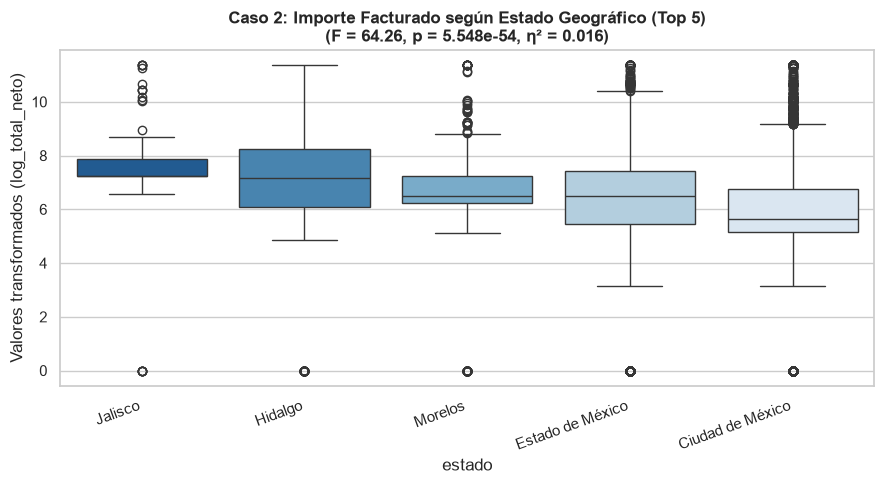


📌 CASO 3: INTERACCIÓN MARCA × TIPO DE PAGO EN FACTURACIÓN
• Factores evaluados: marca_norm × tipo_pago (Muestras: 14,615)
• Variable respuesta: log_total_neto

--- Tabla ANOVA (Tipo II) ---
                                          sum_sq       df          F  PR(>F)  Eta_Parcial
C(Q('marca_norm'))                     7825.9408      3.0  1146.3800     0.0       0.1906
C(Q('tipo_pago'))                      1678.1104      1.0   737.4521     0.0       0.0481
C(Q('marca_norm')):C(Q('tipo_pago'))   2434.0222      3.0   356.5468     0.0       0.0682
Residual                              33238.9835  14607.0        NaN     NaN          NaN


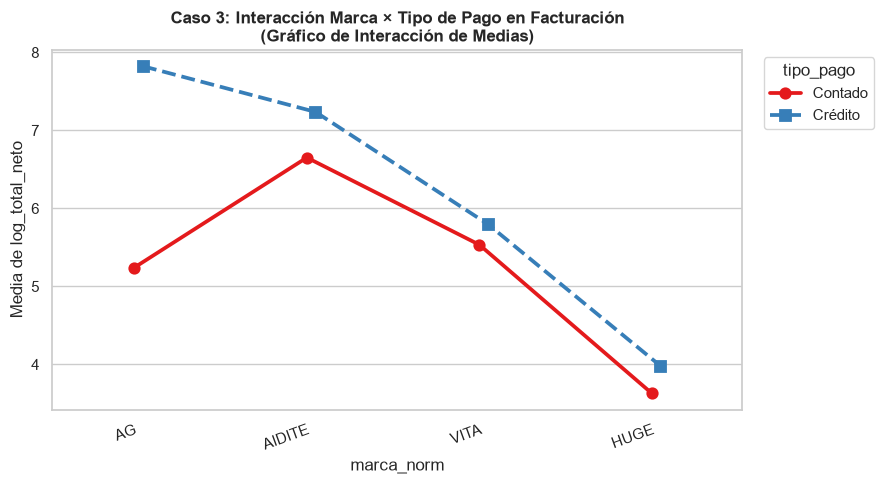

• Interacción (marca_norm × tipo_pago): p = 1.7492e-223 -> Significativa


In [27]:
# Cargamos las columnas necesarias de la hoja de Ventas
ventas = pd.read_excel(
    ARCHIVO_CLV_V2,
    sheet_name="Ventas_CLV_2022_2026",
    usecols=["total_neto", "folio_abreviado", "marca", "estado", "total_unidades"]
)

# Preprocesamos: tratamos outliers con Winsorización y aplicamos logaritmo
ventas["total_neto_clean"] = tratar_outliers_winsorize(ventas["total_neto"]) # Suavizamos valores atípicos
ventas["log_total_neto"] = np.log1p(ventas["total_neto_clean"].clip(lower=0)) # Transformación log(1+x)
ventas["marca_norm"] = ventas["marca"].apply(normalizar_texto).str.upper() # Normalizamos nombres de marcas
ventas["folio_abrev_norm"] = ventas["folio_abreviado"].apply(normalizar_texto).str.upper() # Limpiamos prefijos

# Agrupamos los folios en 3 esquemas comerciales claros
def mapear_pago(val):
    if val in ["A", "B", "XDF"]: return "Contado" # Prefijos de facturas de contado
    if val == "TL": return "Tienda Online" # Ventas web
    if val in ["CDF", "CP"]: return "Crédito" # Ventas a plazos o crédito comercial
    return "Otro"

ventas["tipo_pago"] = ventas["folio_abrev_norm"].apply(mapear_pago) # Creamos la nueva columna
ventas = ventas[ventas["tipo_pago"] != "Otro"].copy() # Conservamos solo las categorías válidas

# CASO 1: ANOVA 1 Vía (Tipo de Pago vs Importe Facturado)
c1 = ejecutar_anova_unifactorial(
    ventas, "log_total_neto", "tipo_pago",
    "Caso 1: Importe Facturado por Tipo de Pago (Contado vs Crédito vs Online)",
    "anova_caso1_ventas_pago"
)
if c1: resumen_global.append(c1)

# CASO 2: ANOVA 1 Vía (Importe Facturado por Región Geográfica)
top_estados = ventas["estado"].value_counts().head(5).index.tolist() # Tomamos los 5 estados con más facturas
ventas_geo = ventas[ventas["estado"].isin(top_estados)].copy() # Filtramos la muestra
c2 = ejecutar_anova_unifactorial(
    ventas_geo, "log_total_neto", "estado",
    "Caso 2: Importe Facturado según Estado Geográfico (Top 5)",
    "anova_caso2_ventas_estado"
)
if c2: resumen_global.append(c2)

# CASO 3: ANOVA Multifactorial (Interacción Marca x Tipo de Pago)
top_marcas = ventas["marca_norm"].value_counts().head(4).index.tolist() # Top 4 marcas más vendidas
ventas_marca_pago = ventas[ventas["marca_norm"].isin(top_marcas)].copy()
c3 = ejecutar_anova_multifactorial(
    ventas_marca_pago, "log_total_neto", "marca_norm", "tipo_pago",
    "Caso 3: Interacción Marca × Tipo de Pago en Facturación",
    "anova_caso3_marca_x_pago"
)
if c3: resumen_global.append(c3)


## 6. Casos de Negocio en CRM (`Negocios_CRM`)
Aquí analizamos el valor de las cotizaciones y oportunidades en el embudo de ventas:
* **Caso 4 (Multifactorial):** ¿El valor del negocio depende de si el cliente es nuevo/existente y si se prospectó en ruta física?
* **Caso 5 (1 Vía):** ¿El pipeline o canal comercial asignado impacta en el tamaño del negocio?



📌 CASO 4: INTERACCIÓN TIPO DE CLIENTE × OPORTUNIDAD EN RUTA EN CRM
• Factores evaluados: tipo_negocio × oportunidad_ruta (Muestras: 4,705)
• Variable respuesta: log_valor_negocio

--- Tabla ANOVA (Tipo II) ---
                                                   sum_sq      df        F  PR(>F)  Eta_Parcial
C(Q('tipo_negocio'))                               3.6806     1.0   0.3150  0.5747       0.0001
C(Q('oportunidad_ruta'))                         441.8610     1.0  37.8131  0.0000       0.0080
C(Q('tipo_negocio')):C(Q('oportunidad_ruta'))      0.3136     1.0   0.0268  0.8699       0.0000
Residual                                       54933.1021  4701.0      NaN     NaN          NaN


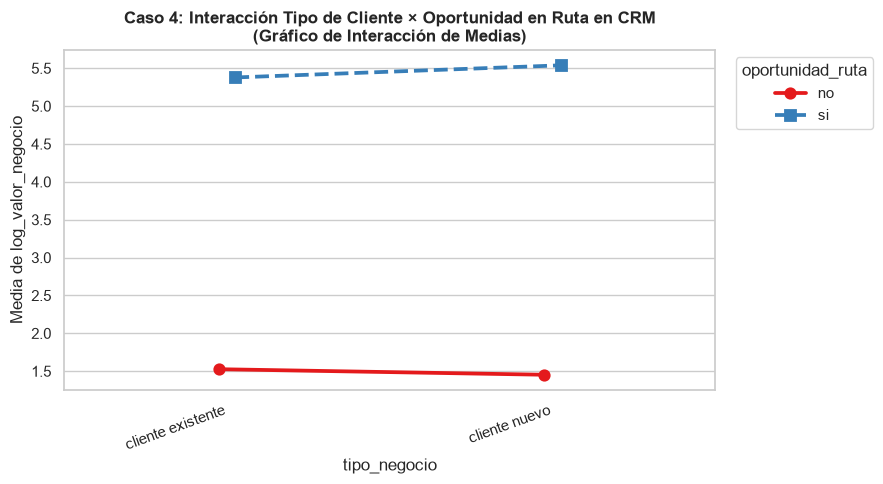

• Interacción (tipo_negocio × oportunidad_ruta): p = 8.6988e-01 -> No significativa

📌 CASO 5: VALOR PREVISTO DEL NEGOCIO POR TIPO DE PIPELINE CRM
• Factor evaluado: nombre_pipeline (4 niveles)
• Variable respuesta: log_valor_negocio (Total de casos: 5,245)
• Homocedasticidad (Levene): Stat = 98.133, p-valor = 8.4964e-62
• Estadístico F: 98.133 | p-valor: 8.4964e-62
• Tamaño del efecto (Eta² parcial): 0.0532
• Conclusión: Sí existen diferencias significativas entre grupos (Rechaza H0).

--- Pruebas Post-Hoc Tukey HSD (Top comparaciones) ---
Pares con diferencia real: 3 de 6
            group1        group2  meandiff  p-adj  lower  upper  reject
educacion continua ventas - main    3.4754    0.0 1.7052 5.2456    True
     mapeo en ruta ventas - main    2.3343    0.0 1.4839 3.1847    True
pipeline de ventas ventas - main    2.2660    0.0 1.9227 2.6092    True


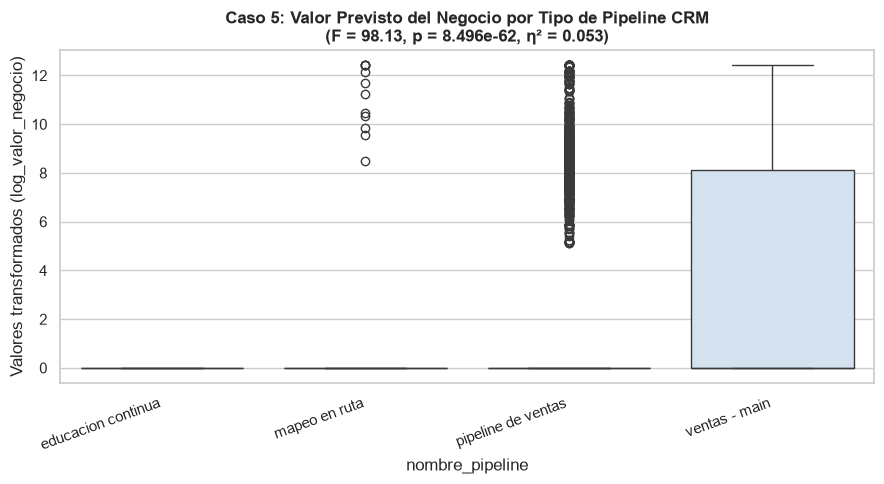

In [28]:
# Cargamos las oportunidades comerciales de CRM
crm = pd.read_excel(
    ARCHIVO_CLV_V2,
    sheet_name="Negocios_CRM",
    usecols=["id_negocio", "tipo_negocio", "oportunidad_ruta", "nombre_pipeline", "valor_negocio"]
)

# Limpiamos tipos de datos y transformamos la variable monetaria
crm["valor_negocio"] = pd.to_numeric(crm["valor_negocio"], errors="coerce") # Convertimos a número
crm = crm.dropna(subset=["valor_negocio"]).copy() # Descartamos registros sin monto
crm["valor_negocio_clean"] = tratar_outliers_winsorize(crm["valor_negocio"]) # Suavizamos outliers
crm["log_valor_negocio"] = np.log1p(crm["valor_negocio_clean"].clip(lower=0)) # Transformación log(1+x)
crm["tipo_negocio"] = crm["tipo_negocio"].apply(normalizar_texto) # Limpiamos categorías
crm["oportunidad_ruta"] = crm["oportunidad_ruta"].apply(normalizar_texto)
crm["nombre_pipeline"] = crm["nombre_pipeline"].apply(normalizar_texto)

# CASO 4: ANOVA Multifactorial (Cliente Nuevo x Oportunidad en Ruta)
crm_filtro = crm[
    crm["tipo_negocio"].isin(["cliente nuevo", "cliente existente"]) &
    crm["oportunidad_ruta"].isin(["si", "no"])
].copy()
c4 = ejecutar_anova_multifactorial(
    crm_filtro, "log_valor_negocio", "tipo_negocio", "oportunidad_ruta",
    "Caso 4: Interacción Tipo de Cliente × Oportunidad en Ruta en CRM",
    "anova_caso4_crm_cliente_x_ruta"
)
if c4: resumen_global.append(c4)

# CASO 5: ANOVA 1 Vía (Pipeline Comercial vs Valor Previsto)
top_pipelines = crm["nombre_pipeline"].value_counts().head(4).index.tolist() # Top 4 canales de venta
crm_pipe = crm[crm["nombre_pipeline"].isin(top_pipelines)].copy()
c5 = ejecutar_anova_unifactorial(
    crm_pipe, "log_valor_negocio", "nombre_pipeline",
    "Caso 5: Valor Previsto del Negocio por Tipo de Pipeline CRM",
    "anova_caso5_crm_pipeline"
)
if c5: resumen_global.append(c5)


## 7. Casos de Cadena de Suministro: Almacén y Compras
* **Caso 6:** ¿El nivel físico de existencias varía significativamente entre marcas comerciales?
* **Caso 7:** ¿Cómo interactúa la marca con el año de compra en el volumen de unidades adquiridas a proveedores?

> **Nota técnica para estudiantes:** En la hoja de `Histórico_Compras`, la columna directa `marca` no existe de fábrica; pero como buenos analistas, **cruzamos las compras con la hoja de existencias usando la llave `articulo_id`** para recuperar la marca exacta de cada producto.



📌 CASO 6: NIVELES DE STOCK DE INVENTARIO SEGÚN MARCA COMERCIAL
• Factor evaluado: marca_norm (5 niveles)
• Variable respuesta: log_existencias (Total de casos: 2,671)
• Homocedasticidad (Levene): Stat = 53.828, p-valor = 1.0966e-43
• Estadístico F: 161.641 | p-valor: 5.1253e-124
• Tamaño del efecto (Eta² parcial): 0.1952
• Conclusión: Sí existen diferencias significativas entre grupos (Rechaza H0).

--- Pruebas Post-Hoc Tukey HSD (Top comparaciones) ---
Pares con diferencia real: 8 de 10
        group1         group2  meandiff  p-adj   lower   upper  reject
        AIDITE AMANN GIRRBACH   -1.5728 0.0000 -1.8236 -1.3220    True
        AIDITE      ANAX DENT   -2.0026 0.0000 -2.3194 -1.6858    True
        AIDITE       CREATION   -2.1700 0.0000 -2.4333 -1.9067    True
        AIDITE           VITA   -1.8026 0.0000 -2.0092 -1.5960    True
AMANN GIRRBACH      ANAX DENT   -0.4298 0.0006 -0.7234 -0.1363    True


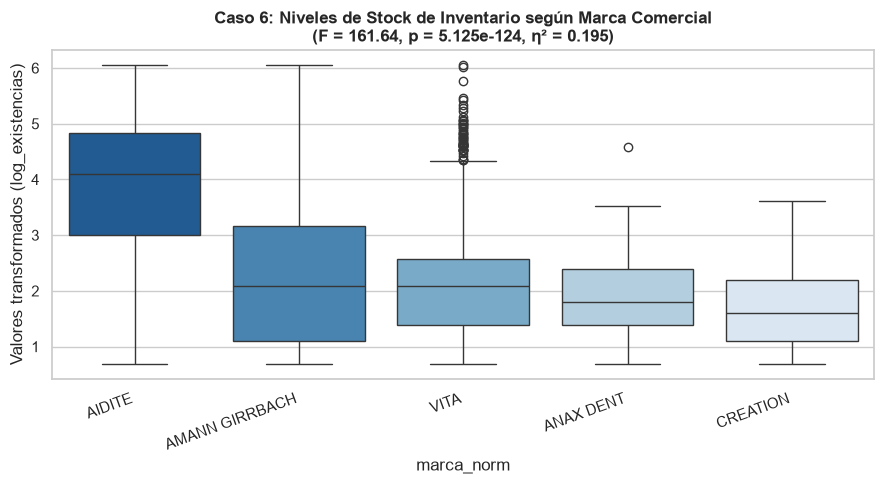


📌 CASO 7: INTERACCIÓN MARCA × AÑO EN VOLUMEN DE COMPRAS A PROVEEDORES
• Factores evaluados: marca_norm × año (Muestras: 2,753)
• Variable respuesta: log_unidades

--- Tabla ANOVA (Tipo II) ---
                                   sum_sq      df         F  PR(>F)  Eta_Parcial
C(Q('marca_norm'))               708.0337     3.0  129.9758  0.0000       0.1245
C(Q('año'))                        1.3364     2.0    0.3680  0.6922       0.0003
C(Q('marca_norm')):C(Q('año'))   125.3437     6.0   11.5049  0.0000       0.0246
Residual                        4977.1332  2741.0       NaN     NaN          NaN


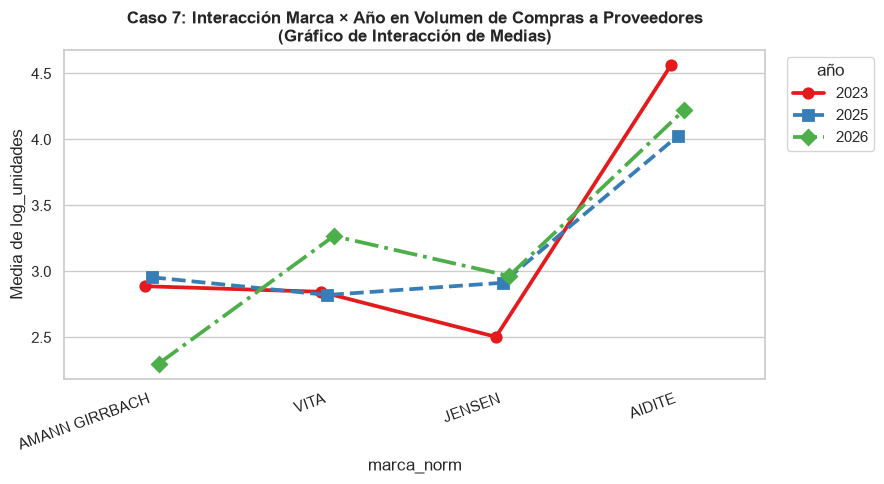

• Interacción (marca_norm × año): p = 9.4538e-13 -> Significativa


In [29]:
# Cargamos las existencias en almacén
existencias = pd.read_excel(
    ARCHIVO_CLV_V2,
    sheet_name="Existencias_04_09_2026",
    usecols=["articulo_id", "marca", "existencias", "valor_total_inventario"]
)
existencias["existencias"] = pd.to_numeric(existencias["existencias"], errors="coerce")
existencias["valor_total_inventario"] = pd.to_numeric(existencias["valor_total_inventario"], errors="coerce")
existencias = existencias.dropna(subset=["existencias", "valor_total_inventario"]).copy()
existencias["log_existencias"] = np.log1p(tratar_outliers_winsorize(existencias["existencias"]).clip(lower=0))
existencias["marca_norm"] = existencias["marca"].apply(normalizar_texto).str.upper()

# CASO 6: ANOVA 1 Vía (Nivel de existencias según Marca)
top_marcas_inv = existencias["marca_norm"].value_counts().head(5).index.tolist()
existencias_top = existencias[existencias["marca_norm"].isin(top_marcas_inv)].copy()
c6 = ejecutar_anova_unifactorial(
    existencias_top, "log_existencias", "marca_norm",
    "Caso 6: Niveles de Stock de Inventario según Marca Comercial",
    "anova_caso6_existencias_marca"
)
if c6: resumen_global.append(c6)

# Cargamos el historial de compras
compras = pd.read_excel(
    ARCHIVO_CLV_V2,
    sheet_name="Histórico_Compras",
    usecols=["fecha", "articulo_id", "unidades", "precio_total_neto"]
)
compras["unidades"] = pd.to_numeric(compras["unidades"], errors="coerce")
compras["fecha"] = pd.to_datetime(compras["fecha"], errors="coerce")
compras["año"] = compras["fecha"].dt.year.astype(str) # Extraemos el año de compra
compras = compras.dropna(subset=["unidades", "año", "articulo_id"]).copy()

# Recuperamos la marca cruzando con la hoja de existencias a través de articulo_id
mapa_marcas = existencias[["articulo_id", "marca_norm"]].drop_duplicates("articulo_id")
compras = compras.merge(mapa_marcas, on="articulo_id", how="inner") # Cruce relacional limpio
compras["log_unidades"] = np.log1p(tratar_outliers_winsorize(compras["unidades"]).clip(lower=0))

# CASO 7: ANOVA Multifactorial (Unidades Compradas por Marca x Año)
top_marcas_compras = compras["marca_norm"].value_counts().head(4).index.tolist()
top_anos = compras["año"].value_counts().head(3).index.tolist()
compras_top = compras[compras["marca_norm"].isin(top_marcas_compras) & compras["año"].isin(top_anos)].copy()
c7 = ejecutar_anova_multifactorial(
    compras_top, "log_unidades", "marca_norm", "año",
    "Caso 7: Interacción Marca × Año en Volumen de Compras a Proveedores",
    "anova_caso7_compras_marca_x_ano"
)
if c7: resumen_global.append(c7)


## 8. Casos Operativos de Rotación y Ventas Históricas
* **Caso 8:** ¿La rotación de piezas despachadas en `Salidas_Almacen` tiene estacionalidad mensual?
* **Caso 9:** ¿El desempeño de los representantes de ventas depende de la marca que comercializan?
* **Caso 10:** ¿Los tiempos de entrega de proveedores o los movimientos generales de almacén varían por marca?



📌 CASO 8: ROTACIÓN / SALIDAS DE ALMACÉN SEGÚN MES
• Factor evaluado: mes (6 niveles)
• Variable respuesta: log_salidas (Total de casos: 14,836)
• Homocedasticidad (Levene): Stat = 22.716, p-valor = 8.7950e-23
• Estadístico F: 16.281 | p-valor: 4.7258e-16
• Tamaño del efecto (Eta² parcial): 0.0055
• Conclusión: Sí existen diferencias significativas entre grupos (Rechaza H0).

--- Pruebas Post-Hoc Tukey HSD (Top comparaciones) ---
Pares con diferencia real: 9 de 15
group1 group2  meandiff  p-adj   lower   upper  reject
     1      3   -0.1228 0.0003 -0.2042 -0.0413    True
     1      4    0.1088 0.0024  0.0262  0.1914    True
     1      6   -0.1078 0.0036 -0.1921 -0.0235    True
    12      3   -0.1030 0.0061 -0.1868 -0.0192    True
    12      4    0.1286 0.0002  0.0437  0.2135    True


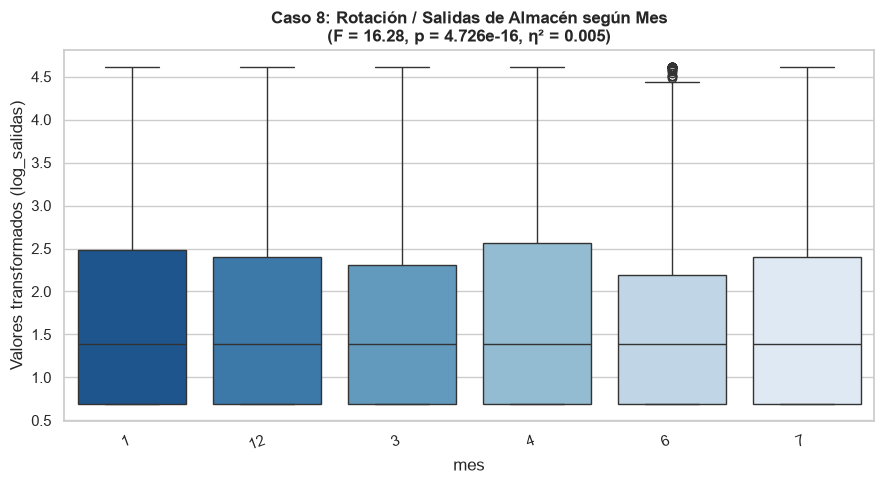


📌 CASO 9: INTERACCIÓN REPRESENTANTE COMERCIAL × MARCA EN FACTURACIÓN HISTÓRICA
• Factores evaluados: vendedor_norm × marca_norm (Muestras: 6,717)
• Variable respuesta: log_neto

--- Tabla ANOVA (Tipo II) ---
                                              sum_sq      df         F  PR(>F)  Eta_Parcial
C(Q('vendedor_norm'))                       311.2283     3.0   23.9888     0.0       0.0106
C(Q('marca_norm'))                         1033.3691     2.0  119.4749     0.0       0.0344
C(Q('vendedor_norm')):C(Q('marca_norm'))    607.9640     6.0   23.4303     0.0       0.0205
Residual                                  28996.6324  6705.0       NaN     NaN          NaN


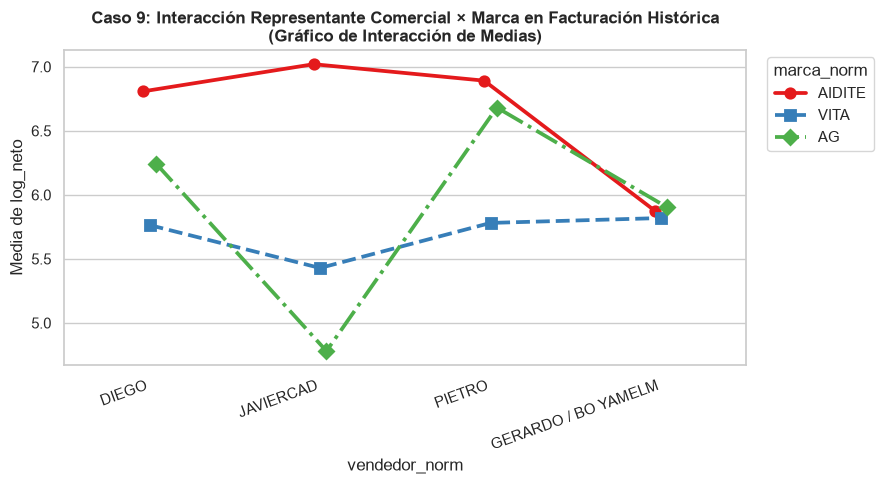

• Interacción (vendedor_norm × marca_norm): p = 1.5002e-27 -> Significativa

📌 CASO 10: VOLUMEN DE MOVIMIENTOS HISTÓRICOS DE ALMACÉN POR MARCA
• Factor evaluado: marca_norm (5 niveles)
• Variable respuesta: log_salidas (Total de casos: 44,704)
• Homocedasticidad (Levene): Stat = 36.936, p-valor = 6.9787e-31
• Estadístico F: 705.589 | p-valor: 0.0000e+00
• Tamaño del efecto (Eta² parcial): 0.0594
• Conclusión: Sí existen diferencias significativas entre grupos (Rechaza H0).

--- Pruebas Post-Hoc Tukey HSD (Top comparaciones) ---
Pares con diferencia real: 8 de 10
group1 group2  meandiff  p-adj   lower   upper  reject
    AG AIDITE    0.6570    0.0  0.5983  0.7157    True
    AG   HUGE    0.7267    0.0  0.6569  0.7964    True
    AG  KOMET   -0.1128    0.0 -0.1766 -0.0489    True
    AG   VITA   -0.1232    0.0 -0.1595 -0.0870    True
AIDITE  KOMET   -0.7697    0.0 -0.8434 -0.6960    True


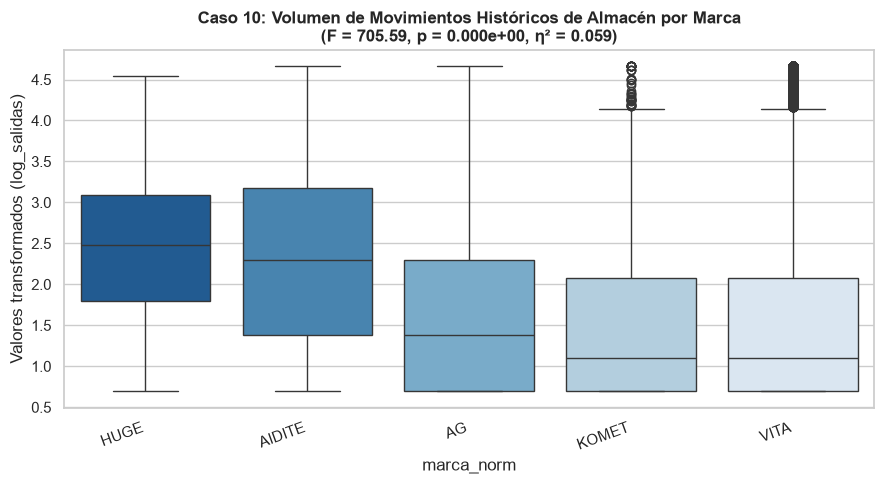

In [30]:
# CASO 8: Rotación y Salidas de Almacén por Mes
salidas = pd.read_excel(
    ARCHIVO_CLV_V2,
    sheet_name="Salidas_Almacen",
    usecols=["mes", "salidas", "marca"]
)
salidas["salidas"] = pd.to_numeric(salidas["salidas"], errors="coerce")
salidas["mes"] = salidas["mes"].astype(str) # Convertimos el mes a texto categórico
salidas = salidas.dropna(subset=["salidas", "mes"]).copy()
salidas["log_salidas"] = np.log1p(tratar_outliers_winsorize(salidas["salidas"]).clip(lower=0))

top_meses = salidas["mes"].value_counts().head(6).index.tolist() # Evaluamos los 6 meses con más movimiento
salidas_mes = salidas[salidas["mes"].isin(top_meses)].copy()
c8 = ejecutar_anova_unifactorial(
    salidas_mes, "log_salidas", "mes",
    "Caso 8: Rotación / Salidas de Almacén según Mes",
    "anova_caso8_salidas_estacionalidad"
)
if c8: resumen_global.append(c8)

# CASO 9: Interacción Vendedor x Marca en Histórico de Ventas
if ARCHIVO_COMPLEMENTARIO.exists():
    hventas = pd.read_excel(
        ARCHIVO_COMPLEMENTARIO,
        sheet_name="Histórico_Ventas",
        usecols=["total_neto", "marc", "vendedor"]
    )
    hventas["total_neto"] = pd.to_numeric(hventas["total_neto"], errors="coerce")
    hventas = hventas.dropna(subset=["total_neto"]).copy()
    hventas["log_neto"] = np.log1p(tratar_outliers_winsorize(hventas["total_neto"]).clip(lower=0))
    hventas["vendedor_norm"] = hventas["vendedor"].apply(normalizar_texto).str.upper()
    hventas["marca_norm"] = hventas["marc"].apply(normalizar_texto).str.upper()

    top_vendedores = hventas["vendedor_norm"].value_counts().head(4).index.tolist()
    top_m = hventas["marca_norm"].value_counts().head(3).index.tolist()
    hventas_top = hventas[hventas["vendedor_norm"].isin(top_vendedores) & hventas["marca_norm"].isin(top_m)].copy()
    c9 = ejecutar_anova_multifactorial(
        hventas_top, "log_neto", "vendedor_norm", "marca_norm",
        "Caso 9: Interacción Representante Comercial × Marca en Facturación Histórica",
        "anova_caso9_vendedor_x_marca"
    )
    if c9: resumen_global.append(c9)

# CASO 10: Tiempos de Entrega o Movimientos de Almacén
if ARCHIVO_TIEMPOS.exists():
    tiempos = pd.read_excel(ARCHIVO_TIEMPOS)
    cols_num = tiempos.select_dtypes(include=[np.number]).columns.tolist()
    cols_cat = tiempos.select_dtypes(include=["object"]).columns.tolist()
    if cols_num and cols_cat:
        col_y = cols_num[0]
        col_factor = cols_cat[0]
        tiempos["log_y"] = np.log1p(tratar_outliers_winsorize(tiempos[col_y]).clip(lower=0))
        c10 = ejecutar_anova_unifactorial(
            tiempos, "log_y", col_factor,
            f"Caso 10: Tiempos de Entrega de Proveedores según {col_factor}",
            "anova_caso10_tiempos_proveedores"
        )
        if c10: resumen_global.append(c10)
elif ARCHIVO_COMPLEMENTARIO.exists():
    es = pd.read_excel(
        ARCHIVO_COMPLEMENTARIO,
        sheet_name="Histórico_Entradas_SAlidas",
        usecols=["SALIDAS", "MARCA"]
    )
    es["SALIDAS"] = pd.to_numeric(es["SALIDAS"], errors="coerce")
    es = es.dropna().copy()
    es["log_salidas"] = np.log1p(tratar_outliers_winsorize(es["SALIDAS"]).clip(lower=0))
    es["marca_norm"] = es["MARCA"].apply(normalizar_texto).str.upper()
    top_m = es["marca_norm"].value_counts().head(5).index.tolist()
    es_top = es[es["marca_norm"].isin(top_m)].copy()
    c10 = ejecutar_anova_unifactorial(
        es_top, "log_salidas", "marca_norm",
        "Caso 10: Volumen de Movimientos Históricos de Almacén por Marca",
        "anova_caso10_movimientos_almacen"
    )
    if c10: resumen_global.append(c10)


In [31]:
# Convertimos nuestra lista de resultados en un DataFrame ordenado
df_resumen = pd.DataFrame(resumen_global)

# Guardamos la tabla en archivo CSV para adjuntarla al reporte
archivo_resumen = BASE_DIR / "resultados_anova_resumen.csv"
df_resumen.to_csv(archivo_resumen, index=False, encoding="utf-8-sig")

print("="*80)
print("📊 RESUMEN EJECUTIVO DE LOS 10 CASOS ANOVA - CLV MÉXICO")
print("="*80)
# Mostramos la tabla formateada en pantalla
df_resumen


📊 RESUMEN EJECUTIVO DE LOS 10 CASOS ANOVA - CLV MÉXICO


,Caso,Tipo,Variable_Y,Factores,F_Statistic,P_Valor,Eta_Cuadrado,Significativo
0,Caso 1: Importe Facturado por Tipo de Pago (Co...,1 Vía (Unifactorial),log_total_neto,tipo_pago,499.441,5.584370e-109,0.0300,True
1,Caso 2: Importe Facturado según Estado Geográf...,1 Vía (Unifactorial),log_total_neto,estado,64.259,5.547773e-54,0.0162,True
2,Caso 3: Interacción Marca × Tipo de Pago en Fa...,Multifactorial (2 Vías con Interacción),log_total_neto,marca_norm × tipo_pago,356.547,1.749227e-223,0.0682,True
3,Caso 4: Interacción Tipo de Cliente × Oportuni...,Multifactorial (2 Vías con Interacción),log_valor_negocio,tipo_negocio × oportunidad_ruta,0.027,8.698799e-01,0.0000,False
4,Caso 5: Valor Previsto del Negocio por Tipo de...,1 Vía (Unifactorial),log_valor_negocio,nombre_pipeline,98.133,8.496442e-62,0.0532,True
5,Caso 6: Niveles de Stock de Inventario según M...,1 Vía (Unifactorial),log_existencias,marca_norm,161.641,5.125282e-124,0.1952,True
6,Caso 7: Interacción Marca × Año en Volumen de ...,Multifactorial (2 Vías con Interacción),log_unidades,marca_norm × año,11.505,9.453794e-13,0.0246,True
7,Caso 8: Rotación / Salidas de Almacén según Mes,1 Vía (Unifactorial),log_salidas,mes,16.281,4.725820e-16,0.0055,True
8,Caso 9: Interacción Representante Comercial × ...,Multifactorial (2 Vías con Interacción),log_neto,vendedor_norm × marca_norm,23.430,1.500222e-27,0.0205,True
9,Caso 10: Volumen de Movimientos Históricos de ...,1 Vía (Unifactorial),log_salidas,marca_norm,705.589,0.000000e+00,0.0594,True
